
# Данные о недвижимости в Индиане на 2026 год:

- Автор: Федоров Алексей Владимирович
- Дата: 29.03.2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, ARDRegression, ElasticNet, BayesianRidge, GammaRegressor, HuberRegressor, LassoLars, PassiveAggressiveRegressor, Perceptron
from sklearn.linear_model import OrthogonalMatchingPursuit, PoissonRegressor, QuantileRegressor, SGDRegressor, TheilSenRegressor, TweedieRegressor, LassoLarsIC, RANSACRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, BaggingRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.ensemble import IsolationForest, VotingRegressor
from sklearn.svm import LinearSVR, NuSVR, SVR
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score
from sklearn.cross_decomposition import CCA, PLSCanonical, PLSRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.neighbors import KNeighborsRegressor, RadiusNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb
from sklearn.inspection import permutation_importance

In [2]:
warnings.filterwarnings('ignore') # Игнорировать не критичные ошибки (предупреждения)

### !Ноутбук должен находиться в той же папке, что и исходный датасет

In [24]:
# !pip install git+https://github.com/alf2107/portfolio-ML_projects.git
# %load https://raw.githubusercontent.com/alf2107/portfolio-ML_projects.git/indiana_real_estate_2026.csv
# %load git@github.com:alf2107/portfolio-ML_projects.git
# df = pd.read_csv('Indiana Real Estate Data 2026/indiana_real_estate_2026.csv')
df = pd.read_csv( 'git@github.com:alf2107/portfolio-ML_projects.git')
# df

OSError: [Errno 22] Invalid argument: 'git@github.com:alf2107/portfolio-ML_projects.git'

### Задача: Предсказать стоимость жилья по остальным параметрам датасета


### Описание данных:
- <b>`type`</b> - Общая классификация недвижимости (например, односемейная, многоквартирная, земельная, коммерческая)
- <b>`sub_type`</b> - Классификация свойств гранул (часто отсутствует или фрагментарна)
- <b>`text`</b> - Рекламное описание, составленное агентом по продаже недвижимости
- <b>`listPrice`</b> - Текущая запрашиваемая цена недвижимости в долларах США (целевая переменная)
- <b>`sqft`</b> - Общая жилая площадь в квадратных футах
- <b>`stories`</b> - Количество этажей в здании
- <b>`beds`</b> - Общее количество спален
- <b>`baths`</b> - Общее количество ванных комнат
- <b>`baths_full`</b> - Количество полностью оборудованных ванных комнат
- <b>`baths_full_calc`</b> - Расчетное/стандартное количество полноценных ванных комнат
- <b>`garage`</b> - Количество парковочных мест в гараже 
- <b>`year_built`</b> - Год постройки здания

#### Выведем информацию о датафрейме:

In [1227]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13532 entries, 0 to 13531
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   type             13532 non-null  object 
 1   sub_type         821 non-null    object 
 2   text             13382 non-null  object 
 3   listPrice        13532 non-null  float64
 4   sqft             10918 non-null  float64
 5   stories          10581 non-null  float64
 6   beds             10990 non-null  float64
 7   baths            10402 non-null  float64
 8   baths_full       10924 non-null  float64
 9   baths_full_calc  10942 non-null  float64
 10  garage           9198 non-null   float64
 11  year_built       9675 non-null   float64
dtypes: float64(9), object(3)
memory usage: 1.2+ MB


1. В датафрейме использовано 12 столбцов, из которых 3 имеют тип данных object, остальные - тип данных float64.
2. Всего строк в датафрейме - 13532. Пропуски имеются почти во всех столбцах, за исключением `type` и `listPrice`.
---

#### Проверим наши записи на наличие дубликатов

In [1228]:
df.duplicated().sum()

np.int64(10)

In [1229]:
# Удалим дубликаты
df.drop_duplicates()

,type,sub_type,text,listPrice,sqft,stories,beds,baths,baths_full,baths_full_calc,garage,year_built
0,single_family,NaN,"1975 ""Decor"" Time Capsule hits market for the ...",194900.0,1646.0,1.0,3.0,2.0,2.0,2.0,2.0,1975.0
1,single_family,NaN,"A peaceful country setting, generous acreage, ...",279000.0,2796.0,1.0,3.0,3.0,2.0,2.0,2.0,1984.0
2,single_family,NaN,"**Open House Sunday March 22, from 2-4pm**Luxu...",640000.0,3871.0,2.0,5.0,3.0,2.0,2.0,2.0,1993.0
3,single_family,NaN,Charming 1.5 story home set on 2.25 peaceful a...,279900.0,4080.0,2.0,4.0,2.0,2.0,2.0,2.0,1854.0
4,single_family,NaN,THIS ESTATE HOME IS READY FOR YOU TO RESTORE A...,89900.0,1152.0,1.0,3.0,2.0,1.0,1.0,NaN,1979.0
...,...,...,...,...,...,...,...,...,...,...,...,...
13527,single_family,NaN,What's Special: Close to Trails | Flex Room | ...,284999.0,1605.0,1.0,2.0,2.0,2.0,2.0,2.0,2025.0
13528,land,NaN,The community you've been waiting for....intro...,73000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13529,land,NaN,Silverstone Estates is located west of Lima Ro...,92900.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13530,land,NaN,Tract 12 offers a fantastic opportunity to own...,40500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Подробнее посмотрим на наши данные:

#### 1. Столбец "type":

In [1230]:
# Столбец "type"
df["type"].value_counts()

type
single_family    9821
land             2284
condos            608
multi_family      321
townhomes         271
farm              173
townhome           29
multifamily        15
apartment           9
unknown             1
Name: count, dtype: int64

In [1231]:
# Посмотрим на остальные параметры недвижимости с меткой "unknown"
df1 = df[df['type'] == 'unknown']
df1

,type,sub_type,text,listPrice,sqft,stories,beds,baths,baths_full,baths_full_calc,garage,year_built
185,unknown,NaN,Introducing The St. Martin - Modern Townhome L...,267990.0,1772.0,3.0,3.0,NaN,2.0,2.0,2.0,NaN


- Столбец "type" является категориальным признаком и содержит в себе 9 видов недвижимости и одно неизвестное значение. 
- Посмотрев на описание недвижимости, становится понятно, что "unknown" относится к таунхаусу.
- Также видим что townhomes и townhome - это один и тот же вид недвижимости, но одно из них указано во множественном числе. то же самое и для multifamily и multi_family
  
Преобразуем датафрейм с учетом вышеуказанных пояснений:

In [1232]:
# Заменим unknown на townhome
df.loc[185, 'type'] = 'townhome'

In [1233]:
# Заменим townhomes на townhome, а multifamily на multi_family
df['type'] = df['type'].replace('townhomes', 'townhome')
df['type'] = df['type'].replace('multifamily', 'multi_family')

In [1234]:
df["type"].value_counts()

type
single_family    9821
land             2284
condos            608
multi_family      336
townhome          301
farm              173
apartment           9
Name: count, dtype: int64

#### 2. Столбец "sub_type":

In [1235]:
df["sub_type"].value_counts()

sub_type
condo        608
townhouse    213
Name: count, dtype: int64

В данном столбце всего два значения condo и townhouse, которые занимают около 6%. Остальные строки примерно 94% - с пропусками.\
Указанные значения condo и townhouse также имеются в столбце "type", поэтому исключим данный столбец из датафрейма.

In [1236]:
df = df.drop('sub_type', axis = 1)

In [1237]:
df.head(3)

,type,text,listPrice,sqft,stories,beds,baths,baths_full,baths_full_calc,garage,year_built
0,single_family,"1975 ""Decor"" Time Capsule hits market for the ...",194900.0,1646.0,1.0,3.0,2.0,2.0,2.0,2.0,1975.0
1,single_family,"A peaceful country setting, generous acreage, ...",279000.0,2796.0,1.0,3.0,3.0,2.0,2.0,2.0,1984.0
2,single_family,"**Open House Sunday March 22, from 2-4pm**Luxu...",640000.0,3871.0,2.0,5.0,3.0,2.0,2.0,2.0,1993.0


#### 3. Столбец "text":
Содержит в себе текст объявлений. \
В нем также есть немного строк с пропусками, которые в будущем исключим из анализа.

#### 3. Столбец "listPrice":

Наша целевая переменная. Она не имеет пропусков, никаких дополнительных действий с данным столбцом не требуется.\
Проверим целевую переменную на нормальность распределения с помощью теста Колмогорова-Смирнова:

In [1238]:
d_statictic, p_value = stats.kstest(df['listPrice'], 'norm')
print(f'D-статистика:{d_statictic}') 
print(f'p_value:{p_value}') 

D-статистика:0.9990393142181496
p_value:0.0


Так как p-value < 0.05, то мы отвергаем нулевую гипотезу и делаем вывод, что данные распределены `не нормально`.

#### 4. Остальные столбцы оценим с помощью функции describe:

In [1239]:
df.describe().style.format({'listPrice' : '{:.2f}'})

,listPrice,sqft,stories,beds,baths,baths_full,baths_full_calc,garage,year_built
count,13532.00,10918.000000,10581.000000,10990.000000,10402.000000,10924.000000,10942.000000,9198.000000,9675.000000
mean,371400.21,2107.080234,1.477176,3.315014,2.374447,1.980227,2.025407,2.364536,1977.525478
std,626349.88,1276.492528,0.543021,1.360273,1.202765,0.917135,0.917636,25.413272,42.286040
min,1.00,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1800.000000
25%,175000.00,1402.000000,1.000000,3.000000,2.000000,1.000000,2.000000,2.000000,1950.000000
50%,295000.00,1853.000000,1.000000,3.000000,2.000000,2.000000,2.000000,2.000000,1986.000000
75%,419900.00,2506.000000,2.000000,4.000000,3.000000,2.000000,2.000000,2.000000,2019.000000
max,47900000.00,50762.000000,4.000000,82.000000,32.000000,32.000000,32.000000,2430.000000,2027.000000


In [1240]:
df.describe(include='object')

,type,text
count,13532,13382
unique,7,12677
top,single_family,The Bradford is the perfect ranch-style floorp...
freq,9821,15


 Предварительно видим: 
- Параметр `listPrice` варьируется от 1 до 47900000, среднее значение отличается от 50% процентиля, что предварительно говорит о не нормальном распределении данных (что было проверено выше с помощью теста Колмогорова-Смирнова)
- Нужно посмотреть максимальные и минимальные значения цены на предмет выбросов 
- Общая жилая площадь `sqft` не может быть равна нулю, значит это выброс.
- Год постройки `year_built` не может быть равен 2027, так как в настоящее время 2026 год.

#### Проверим данные на мультиколлинеарность с помощью тепловой карты:

<Axes: >

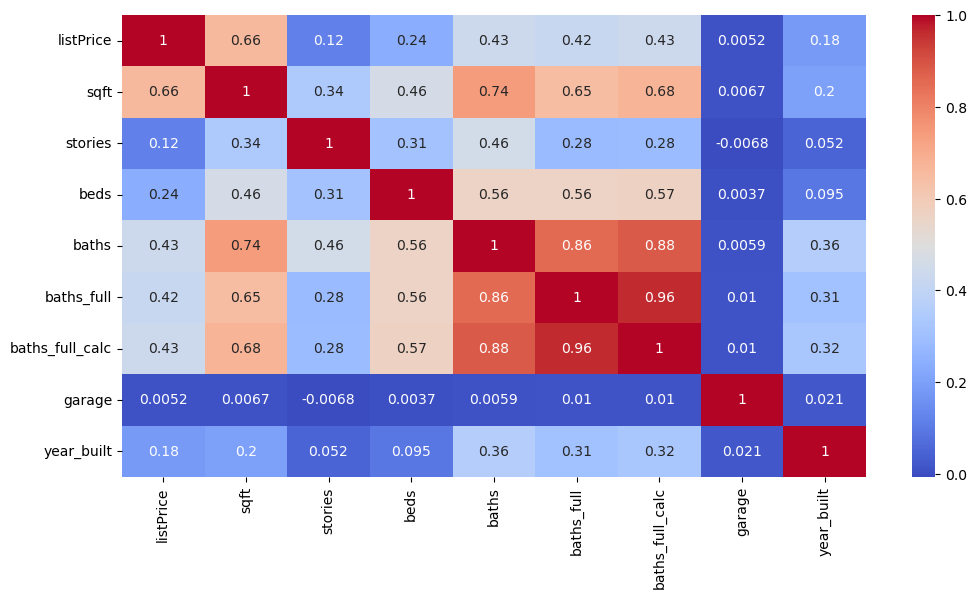

In [1241]:
fig, ax = plt.subplots(figsize=(12, 6))
corr_matrix = df.corr(numeric_only = True)

sns.heatmap(corr_matrix, cmap="coolwarm", annot= True, ax = ax)

Видим сильную мультиколлинеарность между признаками `bath`, `bath_full` и `bath_full_calc`.

#### Заполнение пропущенных значений:
(для числовых даннных: если распределение будет отличаться от нормального, то заполнять пропуски будем `медианой`, если будет нормальным - `средним значением`,
для категориальных данных - будем заполнять наиболее `часто встречающимися значениями`)

In [1242]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13532 entries, 0 to 13531
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   type             13532 non-null  object 
 1   text             13382 non-null  object 
 2   listPrice        13532 non-null  float64
 3   sqft             10918 non-null  float64
 4   stories          10581 non-null  float64
 5   beds             10990 non-null  float64
 6   baths            10402 non-null  float64
 7   baths_full       10924 non-null  float64
 8   baths_full_calc  10942 non-null  float64
 9   garage           9198 non-null   float64
 10  year_built       9675 non-null   float64
dtypes: float64(9), object(2)
memory usage: 1.1+ MB


In [1243]:
def show_missing_stats(tmp0):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': tmp0.isnull().sum(),
        'Доля пропусков': tmp0.isnull().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    
    if missing_stats.empty:
        return "Пропусков в данных нет"
    
    # Форматируем при выводе через Styler
    return (missing_stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='coolwarm'))
show_missing_stats(df)

,Кол-во пропусков,Доля пропусков
text,150,0.0111
sqft,2614,0.1932
stories,2951,0.2181
beds,2542,0.1879
baths,3130,0.2313
baths_full,2608,0.1927
baths_full_calc,2590,0.1914
garage,4334,0.3203
year_built,3857,0.2850


Доля пропусков по столбцам (%):
garage             32.027786
year_built         28.502808
baths              23.130358
stories            21.807567
sqft               19.317174
baths_full         19.272835
baths_full_calc    19.139817
beds               18.785102
text                1.108484
dtype: float64


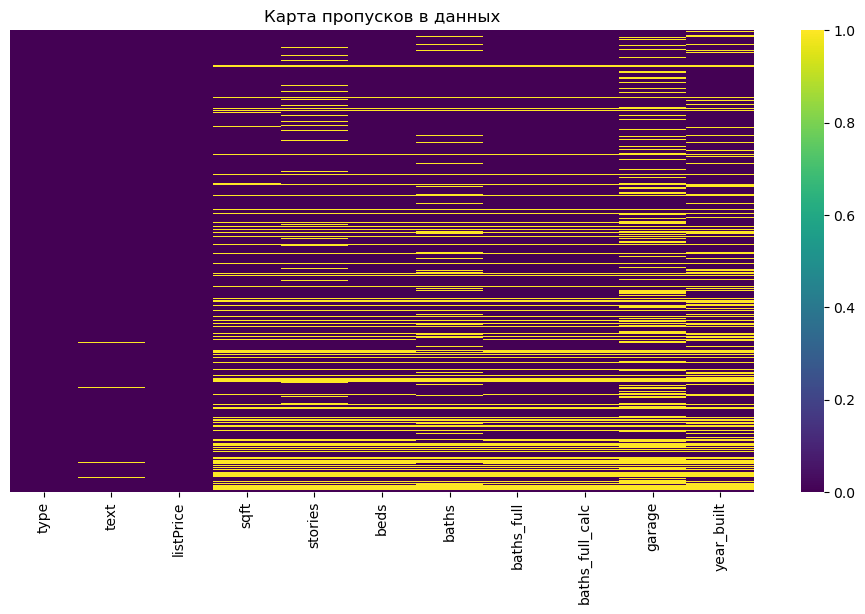

In [1244]:
# Доля пропусков по столбцам
missing_percent = df.isna().mean().sort_values(ascending=False) * 100
print("Доля пропусков по столбцам (%):")
print(missing_percent[missing_percent > 0])

# Визуализация пропусков
plt.figure(figsize=(12, 6))
sns.heatmap(df.isna(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Карта пропусков в данных')
plt.show()


In [1245]:
# так как распределение явно не нормальное, применим для заполнения пропусков - медиану.
imputer = IterativeImputer(max_iter = 10, initial_strategy = 'median', random_state = 42)
X_imputed = imputer.fit_transform(df.iloc[:, 2:11])
df.iloc[:, 2:11] = X_imputed
df

,type,text,listPrice,sqft,stories,beds,baths,baths_full,baths_full_calc,garage,year_built
0,single_family,"1975 ""Decor"" Time Capsule hits market for the ...",194900.0,1646.000000,1.000000,3.000000,2.000000,2.000000,2.000000,2.000000,1975.000000
1,single_family,"A peaceful country setting, generous acreage, ...",279000.0,2796.000000,1.000000,3.000000,3.000000,2.000000,2.000000,2.000000,1984.000000
2,single_family,"**Open House Sunday March 22, from 2-4pm**Luxu...",640000.0,3871.000000,2.000000,5.000000,3.000000,2.000000,2.000000,2.000000,1993.000000
3,single_family,Charming 1.5 story home set on 2.25 peaceful a...,279900.0,4080.000000,2.000000,4.000000,2.000000,2.000000,2.000000,2.000000,1854.000000
4,single_family,THIS ESTATE HOME IS READY FOR YOU TO RESTORE A...,89900.0,1152.000000,1.000000,3.000000,2.000000,1.000000,1.000000,2.230765,1979.000000
...,...,...,...,...,...,...,...,...,...,...,...
13527,single_family,What's Special: Close to Trails | Flex Room | ...,284999.0,1605.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2025.000000
13528,land,The community you've been waiting for....intro...,73000.0,1525.948775,1.344317,3.128399,2.226603,1.940194,2.000311,2.268969,1977.676959
13529,land,Silverstone Estates is located west of Lima Ro...,92900.0,1544.957557,1.342609,3.124722,2.228692,1.940264,2.000162,2.272341,1977.758036
13530,land,Tract 12 offers a fantastic opportunity to own...,40500.0,1494.904283,1.347108,3.134404,2.223192,1.940079,2.000553,2.263462,1977.544546


Доля пропусков по столбцам (%):
text    1.108484
dtype: float64


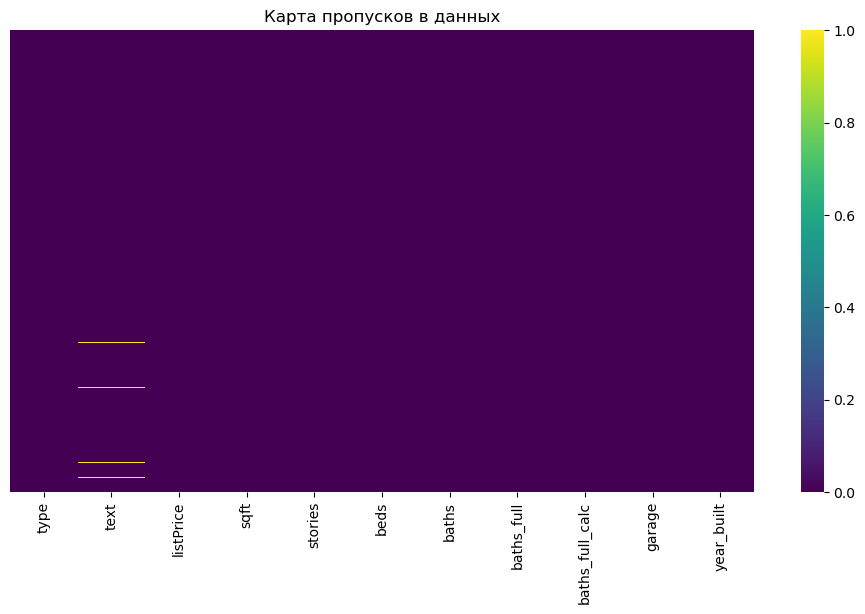

In [1246]:
# Доля пропусков по столбцам
missing_percent = df.isna().mean().sort_values(ascending=False) * 100
print("Доля пропусков по столбцам (%):")
print(missing_percent[missing_percent > 0])

# Визуализация пропусков
plt.figure(figsize=(12, 6))
sns.heatmap(df.isna(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Карта пропусков в данных')
plt.show()

In [1247]:
# Для столбцов stories, beds, baths, baths_full, baths_full_calc, garage, year_built, sqft изменим тип данных float на int, 
# так как эти параметры имеют целочисленные значения (не может быть не целое число этажей в доме, 
# количество парковочных мест в гараже или колтичество ванных комнат в кватртире)
col_df = ['stories', 'beds', 'baths', 'baths_full', 'baths_full_calc', 'garage', 'year_built', 'sqft']
for col in col_df:
    df[col] = df[col].astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13532 entries, 0 to 13531
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   type             13532 non-null  object 
 1   text             13382 non-null  object 
 2   listPrice        13532 non-null  float64
 3   sqft             13532 non-null  int64  
 4   stories          13532 non-null  int64  
 5   beds             13532 non-null  int64  
 6   baths            13532 non-null  int64  
 7   baths_full       13532 non-null  int64  
 8   baths_full_calc  13532 non-null  int64  
 9   garage           13532 non-null  int64  
 10  year_built       13532 non-null  int64  
dtypes: float64(1), int64(8), object(2)
memory usage: 1.1+ MB


##### Удалим столбцы `baths_full` и `baths_full_calc`, так как у них сильная корреляция с `baths` и они в принципе означают одно и то же (все они характеризуют ванные комнаты).
##### Также удалим столбец с объявлениями `text`.

In [1248]:
df = df.drop(['baths_full', 'baths_full_calc', 'text'], axis = 1)
df1 = df.copy()

In [1249]:
df.describe()

,listPrice,sqft,stories,beds,baths,garage,year_built
count,1.353200e+04,13532.000000,13532.000000,13532.000000,13532.000000,13532.000000,13532.000000
mean,3.714002e+05,2041.853385,1.359888,3.223544,2.292787,2.250000,1977.297148
std,6.263499e+05,1221.274641,0.548265,1.252085,1.073046,20.952408,36.191476
min,1.000000e+00,0.000000,0.000000,0.000000,0.000000,1.000000,1751.000000
25%,1.750000e+05,1468.000000,1.000000,3.000000,2.000000,2.000000,1959.000000
50%,2.950000e+05,1760.000000,1.000000,3.000000,2.000000,2.000000,1978.000000
75%,4.199000e+05,2372.000000,2.000000,4.000000,3.000000,2.000000,2004.000000
max,4.790000e+07,50762.000000,8.000000,82.000000,32.000000,2430.000000,2042.000000


In [1250]:
# Удалим строки с годом постройки 2027 (явно ошибка, так как 2027 год еще не наступил)
df = df.drop(df[df['year_built'] > 2026].index)

In [1251]:
# Удалим строки, где stories равны нулю (не может быть количество этажей равно нулю)
df = df.drop(df[df['stories'] == 0].index)

In [1252]:
df.describe()

,listPrice,sqft,stories,beds,baths,garage,year_built
count,1.331700e+04,13317.000000,13317.000000,13317.000000,13317.000000,13317.000000,13317.000000
mean,3.608253e+05,2048.752947,1.381167,3.244650,2.323571,2.251483,1977.674702
std,5.489245e+05,1186.864109,0.525213,1.248457,1.044832,21.120762,36.212426
min,1.000000e+00,0.000000,1.000000,0.000000,0.000000,1.000000,1751.000000
25%,1.799000e+05,1474.000000,1.000000,3.000000,2.000000,2.000000,1960.000000
50%,2.959000e+05,1768.000000,1.000000,3.000000,2.000000,2.000000,1978.000000
75%,4.195000e+05,2381.000000,2.000000,4.000000,3.000000,2.000000,2005.000000
max,4.790000e+07,50762.000000,8.000000,82.000000,32.000000,2430.000000,2026.000000


In [1253]:
# Закодируем категориальный признак type с помощью get_dummies
df_dummies = pd.get_dummies(df['type'], drop_first=False, dtype = int)
df_dummies

,apartment,condos,farm,land,multi_family,single_family,townhome
0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0
2,0,0,0,0,0,1,0
3,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...
13527,0,0,0,0,0,1,0
13528,0,0,0,1,0,0,0
13529,0,0,0,1,0,0,0
13530,0,0,0,1,0,0,0


In [1254]:
df = pd.concat([df, df_dummies], axis = 1).drop('type', axis = 1)

In [1255]:
df_full = df.copy()
df_full

,listPrice,sqft,stories,beds,baths,garage,year_built,apartment,condos,farm,land,multi_family,single_family,townhome
0,194900.0,1646,1,3,2,2,1975,0,0,0,0,0,1,0
1,279000.0,2796,1,3,3,2,1984,0,0,0,0,0,1,0
2,640000.0,3871,2,5,3,2,1993,0,0,0,0,0,1,0
3,279900.0,4080,2,4,2,2,1854,0,0,0,0,0,1,0
4,89900.0,1152,1,3,2,2,1979,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13527,284999.0,1605,1,2,2,2,2025,0,0,0,0,0,1,0
13528,73000.0,1525,1,3,2,2,1977,0,0,0,1,0,0,0
13529,92900.0,1544,1,3,2,2,1977,0,0,0,1,0,0,0
13530,40500.0,1494,1,3,2,2,1977,0,0,0,1,0,0,0



#### Получили датасет без пропусков `df_full`. С ним и будем работать.
---

###  Построим модель регрессии с целевой переменной `listPrice`:

Подберем наилучшую модель из нижеуказанных (на стандартных параметрах, без подбора гиперпараметров): 
- LinearRegression,
- ARDRegression,
- BaggingRegressor,
- ElasticNet,
- BayesianRidge,
- GammaRegressor,
- HuberRegressor,
- LassoLars,
- PassiveAggressiveRegressor,
- OrthogonalMatchingPursuit,
- PoissonRegressor,
- QuantileRegressor,
- SGDRegressor,
- TheilSenRegressor,
- TweedieRegressor
- AdaBoostRegressor,
- GradientBoostingRegressor,
- ExtraTreesRegressor,
- HistGradientBoostingRegressor,
- RandomForestRegressor,
- IsolationForest,
- LinearSVR,
- NuSVR,
- SVR,
- CatBoostRegressor,
- LGBMRegressor,
- XGBRegressor,
- DecisionTreeRegressor,
- ExtraTreeRegressor,
- GaussianProcessRegressor,
- KernelRidge,
- KNeighborsRegressor,
- LassoLarsIC,
- MLPRegressor,
- PLSRegression,
- RANSACRegressor,
- TransformedTargetRegressor

In [1256]:
# Разделим датафрейм на признаки и целевую переменные
X = df_full.drop('listPrice', axis = 1)
y = df_full['listPrice']

# Разделим данные на тестовую и обучающую выборки
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state = 42, shuffle = True)

# Масштабируем данные
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

# Построим модель регрессии
model_name = [LinearRegression(), RANSACRegressor(), GradientBoostingRegressor(), AdaBoostRegressor(n_estimators = 30), TransformedTargetRegressor(),
ARDRegression(), ElasticNet(), BayesianRidge(), GammaRegressor(), HuberRegressor(),
LassoLars(), PassiveAggressiveRegressor(), OrthogonalMatchingPursuit(), PoissonRegressor(), QuantileRegressor(), SGDRegressor(),
TheilSenRegressor(), TweedieRegressor(),  RandomForestRegressor(), ExtraTreesRegressor(),
HistGradientBoostingRegressor(),  IsolationForest(), LinearSVR(), BaggingRegressor(),
NuSVR(), SVR(), CatBoostRegressor(verbose=False), LGBMRegressor(), XGBRegressor(), DecisionTreeRegressor(), ExtraTreeRegressor(), GaussianProcessRegressor(),
KernelRidge(), KNeighborsRegressor(), LassoLarsIC(), MLPRegressor(), PLSRegression()]


exit_df = pd.DataFrame()
for name in model_name:
    print(f'{name}:')
    model = name
    model.fit(x_train_scaler, y_train)
    y_pred = model.predict(x_test_scaler)
    
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    list_metric = pd.DataFrame({'name' : [name], 'r2' : [r2], 'mae' : [mae], 'mse' : [mse]})
    list_metric = list_metric.round(2)
    exit_df = pd.concat([exit_df,list_metric],  axis = 0)

LinearRegression():
RANSACRegressor():
GradientBoostingRegressor():
AdaBoostRegressor(n_estimators=30):
TransformedTargetRegressor():
ARDRegression():
ElasticNet():
BayesianRidge():
GammaRegressor():
HuberRegressor():
LassoLars():
PassiveAggressiveRegressor():
OrthogonalMatchingPursuit():
PoissonRegressor():
QuantileRegressor():
SGDRegressor():
TheilSenRegressor():
TweedieRegressor():
RandomForestRegressor():
ExtraTreesRegressor():
HistGradientBoostingRegressor():
IsolationForest():
LinearSVR():
BaggingRegressor():
NuSVR():
SVR():
<catboost.core.CatBoostRegressor object at 0x0000015AC5661BD0>:
LGBMRegressor():
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000566 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 471
[LightGBM] [Info] Number of data points in the train set: 9321, number of used features: 12
[LightGBM] [Info] Start trainin

In [1257]:
# Отсортируем результаты в порядке убывания по метрике R2
exit_df.sort_values(by = 'r2', ascending = False).head(5)

,name,r2,mae,mse
0,"XGBRegressor(base_score=None, booster=None, ca...",0.75,76971.72,3.101553e+10
0,"(ExtraTreeRegressor(random_state=1616964801), ...",0.75,75607.71,3.043627e+10
0,([DecisionTreeRegressor(criterion='friedman_ms...,0.74,85667.36,3.107020e+10
0,KNeighborsRegressor(),0.74,78547.65,3.124165e+10
0,"(DecisionTreeRegressor(max_features=1.0, rando...",0.72,75426.89,3.436747e+10


In [1274]:
# Параметры лучшей модели
print(exit_df.sort_values(by = 'r2', ascending = False).iloc[0, 0])
print(exit_df.sort_values(by = 'r2', ascending = False).iloc[2, 0])

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)
GradientBoostingRegressor()


##### Наилучший результат по метрике коэффициент детерминации получен для модели `XGBRegressor` , третий по величине -  `GradientBoostingRegressor`.
##### Подберем для модели `XGBRegressor` оптимальные гиперпараметры:

In [1259]:
# Код подбора оптимальных гиперпараметров закомментирован, так как он занимает длительное время. 
# При необходимости можно снять комментарии и запустить код
# -------------------------------------------------------------------------------------------------

# param_grid = {
#     'n_estimators' : [45, 50, 55], 
#     'learning_rate' : [0.04, 0.05, 0.06],
#     'max_depth' : [8, 9, 10],
#     'gamma' : [0, 0.01],
#     'reg_lambda' : [0.01, 0],
#     'alpha' : [0, 0.01],
#     'min_child_weight' : [7, 8, 9],
#     'subsample' : [0.4, 0.5, 0.6],
#     'colsample_bytree' : [0.9, 1.0, 1.1], 
#     'objective' : ['reg:squarederror', 'reg:absoluteerror'],
#     'eval_metric' : ['rmse', 'mae', 'mape'],
# }

# grid_search = GridSearchCV(XGBRegressor(), param_grid = param_grid, scoring = 'r2', n_jobs = -1, cv = 3, verbose = 1)  
# grid_search.fit(x_train_scaler, y_train)
# print("Лучшие параметры:", grid_search.best_params_)
# print("Лучший R2:", grid_search.best_score_) 
# best_model = grid_search.best_estimator_
# print(best_model.get_params())  

In [1260]:
# На полученных гиперпараметрах R2 модели показал не очень высокий результат. Подберем гиперпараметры вручную.
model_XGBRegressor = XGBRegressor(
    gamma = 0, 
    alpha = 0, 
    eval_metric = 'rmse', 
    objective = 'reg:squarederror', 
    reg_lambda = 0.35, 
    n_estimators = 35, 
    colsample_bytree = 0.93, 
    learning_rate = 0.05, 
    max_depth = 17,
    min_child_weight = 8,
    subsample = 0.5
)
model_XGBRegressor.fit(x_train_scaler, y_train)
y_pred = model_XGBRegressor.predict(x_test_scaler)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f'r2: {r2:.3f}')
print(f'mae: {mae:.2f}')
print (f'mse:{mse:.2f}')

r2: 0.755
mae: 84966.30
mse:29805999616.70


##### Проверим полученную модель на переобучение:

In [1261]:
# Проверка на переобучение (переобучение, если R²(train) - R²(test) > 0.1-0.2). В нашем случае переобучение отсутствует
train_r2 = model_XGBRegressor.score(x_train_scaler, y_train)
test_r2 = model_XGBRegressor.score(x_test_scaler, y_test)
print(f"R² (train): {train_r2:.3f}")
print(f"R² (test): {test_r2:.3f}")
print(f"Разница: {train_r2 - test_r2:.3f}")

R² (train): 0.395
R² (test): 0.755
Разница: -0.360


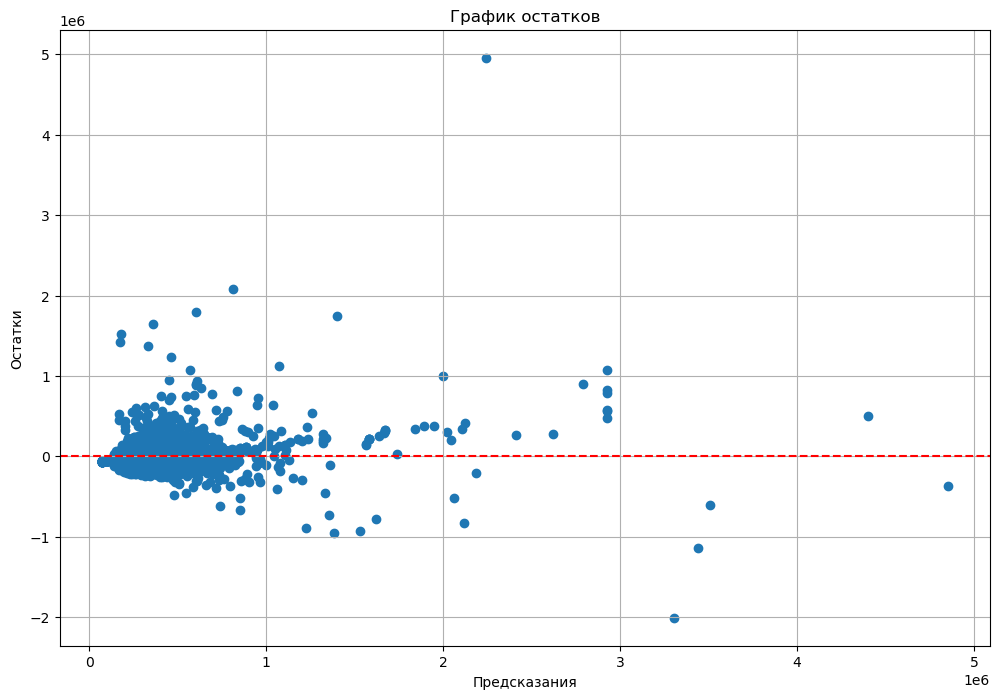

In [1262]:
# Построим график остатков
residuals = y_test - y_pred
plt.figure(figsize=(12, 8))
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Предсказания')
plt.ylabel('Остатки')
plt.title("График остатков")
plt.grid()
plt.show()

Важность признаков (по убыванию):
sqft: 1.0044 ± 0.0675
land: 0.4374 ± 0.0367
year_built: 0.2123 ± 0.0210
baths: 0.0905 ± 0.0027
farm: 0.0251 ± 0.0037
beds: 0.0239 ± 0.0054
garage: 0.0112 ± 0.0010
multifamily: 0.0071 ± 0.0009
stories: 0.0039 ± 0.0006
condos: 0.0034 ± 0.0003
multi_family: 0.0022 ± 0.0003
single_family: 0.0000 ± 0.0000
apartment: 0.0000 ± 0.0000


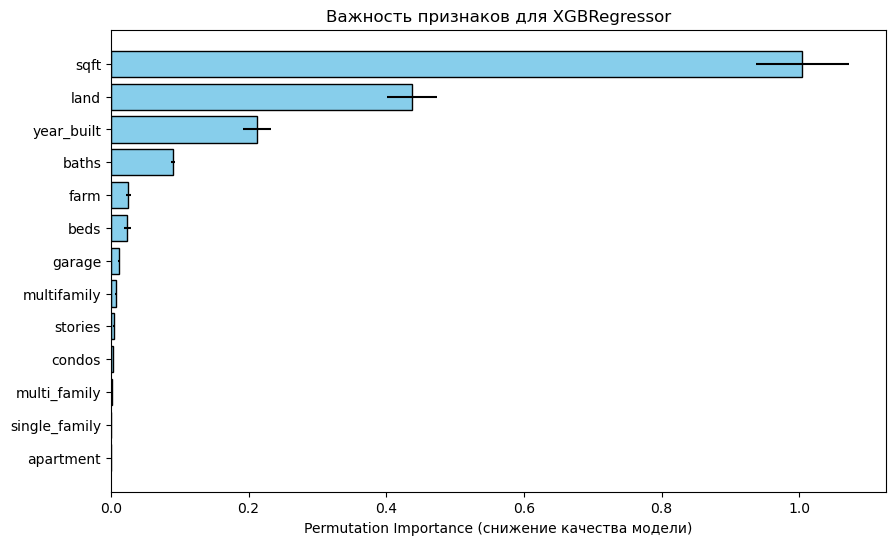

In [1263]:
# Вычисление важности признаков в данной модели
perm_importance = permutation_importance(
    estimator=model_XGBRegressor,
    X=x_test_scaler,
    y=y_test,
    n_repeats=10,           # число перестановок для каждого признака
    random_state=42,
    scoring='r2'  # метрика качества (можно использовать 'r2', 'neg_mean_absolute_error' и др.)
)

# Средние значения важности
importances_mean = perm_importance.importances_mean

# Стандартные отклонения
importances_std = perm_importance.importances_std

# Индексы признаков, отсортированные по важности
sorted_idx = importances_mean.argsort()[::-1]  # убывание

# Вывод результатов
feature_names = ['sqft', 'stories', 'beds', 'baths', 'garage', 'year_built', 'apartment', 'condos', 'farm', 'land', 'multi_family',	'multifamily', 'single_family', 'townhome']

print("Важность признаков (по убыванию):")
for idx in sorted_idx:
    print(f"{feature_names[idx]}: {importances_mean[idx]:.4f} ± {importances_std[idx]:.4f}")
    
# Визуализация
plt.figure(figsize=(10, 6))
plt.barh(
    [feature_names[i] for i in sorted_idx],
    importances_mean[sorted_idx],
    xerr=importances_std[sorted_idx],
    color='skyblue',
    edgecolor='black'
)
plt.xlabel('Permutation Importance (снижение качества модели)')
plt.title('Важность признаков для XGBRegressor')
plt.gca().invert_yaxis()  # сортировка от самого важного
plt.show()

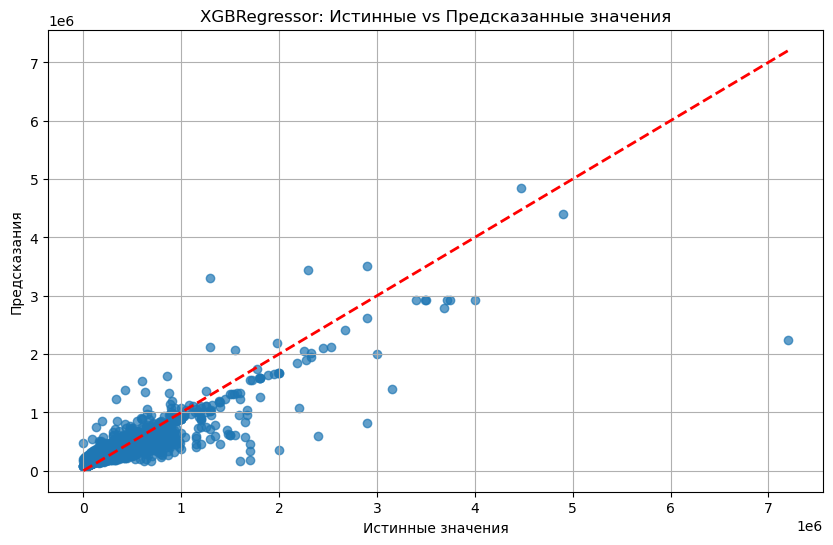

In [1264]:
# Построим график зависимости предсказанных значений от истинных для модели XGBRegressor
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Истинные значения")
plt.ylabel("Предсказания")
plt.title("XGBRegressor: Истинные vs Предсказанные значения")
plt.grid()
plt.show()

#### Вывод: модель не плохая, так как большинство значений расположены вдоль диагонали (красная линия)

In [1265]:
df_full

,listPrice,sqft,stories,beds,baths,garage,year_built,apartment,condos,farm,land,multi_family,single_family,townhome
0,194900.0,1646,1,3,2,2,1975,0,0,0,0,0,1,0
1,279000.0,2796,1,3,3,2,1984,0,0,0,0,0,1,0
2,640000.0,3871,2,5,3,2,1993,0,0,0,0,0,1,0
3,279900.0,4080,2,4,2,2,1854,0,0,0,0,0,1,0
4,89900.0,1152,1,3,2,2,1979,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13527,284999.0,1605,1,2,2,2,2025,0,0,0,0,0,1,0
13528,73000.0,1525,1,3,2,2,1977,0,0,0,1,0,0,0
13529,92900.0,1544,1,3,2,2,1977,0,0,0,1,0,0,0
13530,40500.0,1494,1,3,2,2,1977,0,0,0,1,0,0,0


In [1266]:
# Проверим работу нашей модели на новых данных
# Для этого последовательно подадим данные в параметры sqft, stories, beds, baths, garage, year_built, apartment, condos, farm, land, multi_family, single_family, townhome
new_data = [[1000, 1, 2, 2, 2, 2025, 0, 0, 0, 0, 0, 0, 1]]
y__pred_2 = model_XGBRegressor.predict(new_data)
y__pred_2

array([2408805.], dtype=float32)

---
##### Теперь построим модель GradientBoostingRegressor:

In [1267]:
# Выведем гиперпараметры, используемые по умолчанию в GradientBoostingRegressor
model_GradientBoostingRegressor = GradientBoostingRegressor(random_state = 42)
model_GradientBoostingRegressor.fit(x_train_scaler, y_train)
y_pred = model_GradientBoostingRegressor.predict(x_test_scaler)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f'r2: {r2:.3f}')
print(f'mae: {mae:.2f}')
print (f'mse:{mse:.2f}')
model_GradientBoostingRegressor.get_params()

r2: 0.743
mae: 85785.68
mse:31258642557.45


{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'squared_error', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}

In [1268]:
# Попробуем немного поиграться с гиперпараметры, чтобы посмотреть сможем ли повысить этими действиями R2 без переобучения модели
model_GradientBoostingRegressor = GradientBoostingRegressor(
    random_state = 42,
    alpha = 0.9,
    ccp_alpha = 0.0,
    criterion = 'friedman_mse',
    learning_rate = 0.1,
    loss = 'squared_error',
    max_depth = 5,
    max_features = None,
    min_samples_leaf = 1,
    min_samples_split = 2, 
    n_estimators = 100,
    subsample = 0.9,
    tol = 0.001,
    validation_fraction = 0.01,
    warm_start = False                                                           
)
model_GradientBoostingRegressor.fit(x_train_scaler, y_train)
y_pred = model_GradientBoostingRegressor.predict(x_test_scaler)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f'r2: {r2:.3f}')
print(f'mae: {mae:.2f}')
print (f'mse:{mse:.2f}')
print ('------------------------------')
# Проверка на переобучение (переобучение, если R²(train) - R²(test) > 0.1-0.2).
train_r2 = model_GradientBoostingRegressor.score(x_train_scaler, y_train)
test_r2 = model_GradientBoostingRegressor.score(x_test_scaler, y_test)
print(f"R² (train): {train_r2:.3f}")
print(f"R² (test): {test_r2:.3f}")
print(f"Разница: {train_r2 - test_r2:.3f}")

r2: 0.750
mae: 78414.19
mse:30389647333.06
------------------------------
R² (train): 0.960
R² (test): 0.750
Разница: 0.210


##### Получили переобученную модель

Важность признаков (по убыванию):
sqft: 1.3632 ± 0.0877
land: 0.5634 ± 0.0643
year_built: 0.1430 ± 0.0264
baths: 0.0484 ± 0.0027
farm: 0.0304 ± 0.0092
beds: 0.0235 ± 0.0020
condos: 0.0097 ± 0.0025
stories: 0.0061 ± 0.0021
garage: 0.0057 ± 0.0031
multifamily: 0.0032 ± 0.0014
single_family: 0.0002 ± 0.0005
apartment: 0.0000 ± 0.0000
multi_family: -0.0008 ± 0.0006


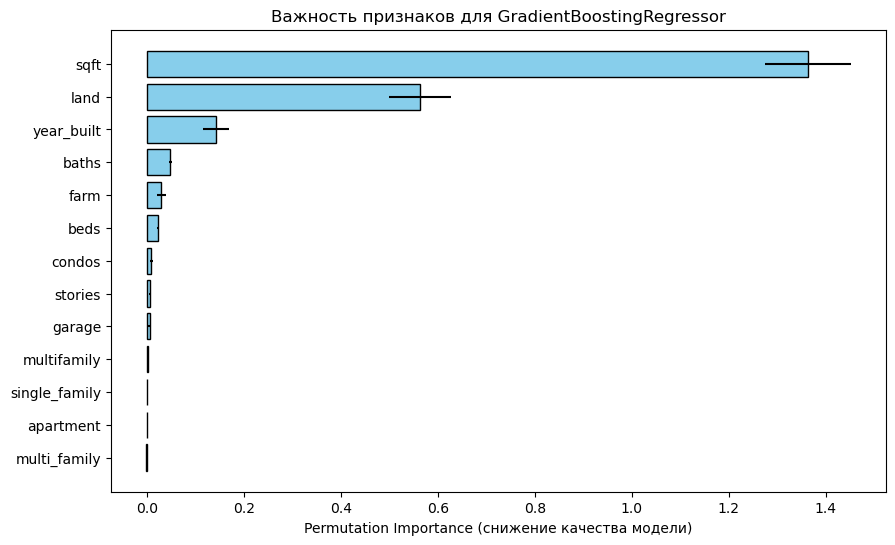

In [1269]:
# Вычисление важности признаков в данной модели
perm_importance = permutation_importance(
    estimator=model_GradientBoostingRegressor,
    X=x_test_scaler,
    y=y_test,
    n_repeats=10,           # число перестановок для каждого признака
    random_state=42,
    scoring='r2'  # метрика качества (можно использовать 'r2', 'neg_mean_absolute_error' и др.)
)

# Средние значения важности
importances_mean = perm_importance.importances_mean

# Стандартные отклонения
importances_std = perm_importance.importances_std

# Индексы признаков, отсортированные по важности
sorted_idx = importances_mean.argsort()[::-1]  # убывание

# Вывод результатов
feature_names = ['sqft', 'stories', 'beds', 'baths', 'garage', 'year_built', 'apartment', 'condos', 'farm', 'land', 'multi_family',	'multifamily', 'single_family', 'townhome']

print("Важность признаков (по убыванию):")
for idx in sorted_idx:
    print(f"{feature_names[idx]}: {importances_mean[idx]:.4f} ± {importances_std[idx]:.4f}")
    
# Визуализация
plt.figure(figsize=(10, 6))
plt.barh(
    [feature_names[i] for i in sorted_idx],
    importances_mean[sorted_idx],
    xerr=importances_std[sorted_idx],
    color='skyblue',
    edgecolor='black'
)
plt.xlabel('Permutation Importance (снижение качества модели)')
plt.title('Важность признаков для GradientBoostingRegressor')
plt.gca().invert_yaxis()  # сортировка от самого важного
plt.show()

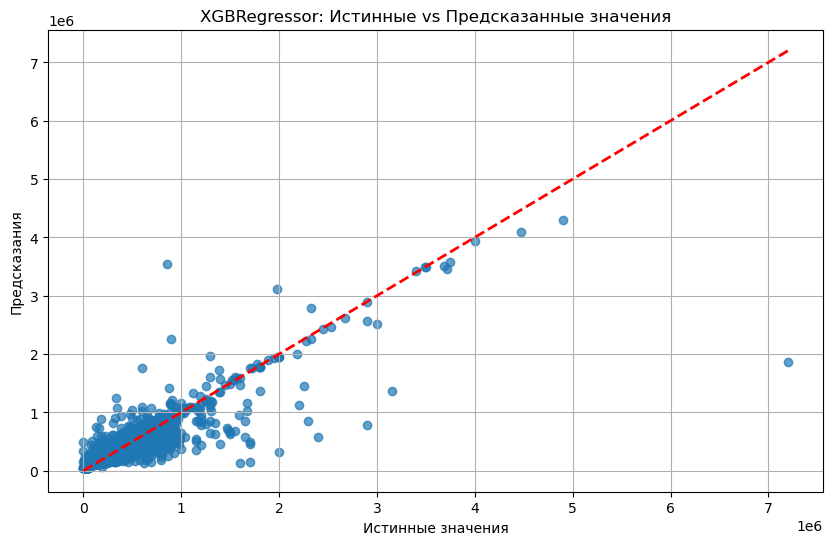

In [1270]:
# Построим график зависимости предсказанных значений от истинных для модели XGBRegressor
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Истинные значения")
plt.ylabel("Предсказания")
plt.title("XGBRegressor: Истинные vs Предсказанные значения")
plt.grid()
plt.show()

### Итоговый вывод:
- Датасет имеет много пропусков, так как не было ТЗ на действия с пропусками, произведена замена с помощью `IterativeImputer`
- Категориальные данные были преобразованы в бинарные признаки с помощью `get_dummies`
- Из датасета были исключены лишнние столбцы (коррелирующие между собой признаки, текстовые данные с объявлением о недвижимости и т.п.)
- Исключены явные выбросы - номера этажей недвижимости, равные нулю, и год постройки недвижимости, превышающий 2026 год.
- Подобраны оптимальные модели регрессии из библиотеки `sklearn`, а также дополнительно модели `CatBoostRegressor`, `LGBMRegressor`, `XGBRegressor`
- Моделями с первой и третьей по величине метрикой R2 (коэффициент детерминации) оказались `XGBRegressor` и `GradientBoostingRegressor`
- Модель на основе `XGBRegressor` показала R2 = 0.755
- Модель на основе `GradientBoostingRegressor` показала R2 = 0.75, но модель переобучается на тестовых данных.
- Для обоих моделей наиболее важными признаками являются `sqft` (площадь), `land` (вид недвижимости), `year_built` (год постройки)